# Jude 2026 intended speech: exploring the Study

The neuralset **`Study`** that turns the Dryad `.mat` blocks into one standardized **events DataFrame**, plus reading each event back through its extractor.

Each `.mat` block is a continuous recording with many cued trials inside, so **one block = one timeline** (121 task blocks). Each timeline emits:
- two whole-block neural streams `(n_ch, n_bins)` at 100 Hz in Study order:
  - `SpikeCounts` (threshold crossings)
  - `BandPower` (spike-band power)
- per trial, a cue `Stimulus` over the delay and a one-bin go-cue `Stimulus`
- per trial, the cued unit: `Phoneme`, `Word` or `Sentence` with `text` and `phonemes`, or `Action` for movements, syllables and rest
- `Intertrial` rows where trials leave a gap

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import neuralshed.events  # noqa: F401, registers the custom event types
from neuralshed import viz
from neuralshed.extractors import NeuralFeatureExtractor, PhonemeEncoder
from neuralshed.datasets.jude_2026_speech import study
from neuralshed.datasets.utils import dataset_dir
from neuralset.events.etypes import Event
from neuralset.events.study import STUDIES
from neuralset.extractors import LabelEncoder

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("jude_2026_speech") / "data"  # the Study base appends the class-name folder
print("Jude2026IntendedSpeech registered:", "Jude2026IntendedSpeech" in STUDIES)
for t in ("SpikeCounts", "BandPower", "Intertrial", "Stimulus", "Phoneme", "Word", "Sentence", "Action"):
    print(f"  {t:12s} registered:", t in Event._CLASSES)

FS = 50.0  # the authors' decoder rate, 10 ms bins compressed to 20 ms

Jude2026IntendedSpeech registered: True
  SpikeCounts  registered: True
  BandPower    registered: True
  Intertrial   registered: True
  Stimulus     registered: True
  Phoneme      registered: True
  Word         registered: True
  Sentence     registered: True
  Action       registered: True


In [2]:
s = study.Jude2026IntendedSpeech(path=root)
s.download()
print("study   :", s.__class__.__name__)
print("path    :", s.path)
print("aliases :", s.aliases)
print("licence :", s.licence)
print("requires:", s.requirements)

2026-10-15 12:10:25 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech.


2026-10-15 12:10:45 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech (skipped 0 non-owned items).


study   : Jude2026IntendedSpeech
path    : /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech
aliases : ('jude_2026_speech', 'anarthria-speech-bci')
licence : CC0-1.0
requires: ('scipy',)


## 1. Timelines, one per task block

The 121 blocks of `utils.SESSION_BLOCKS` become timelines, the 19 excluded files never do. `task_family`, `vocab`, `loop_type`, `date` and `post_implant_day` ride the timeline and broadcast to every event row.

In [3]:
timelines = list(s.iter_timelines())
tldf = pd.DataFrame(timelines)
print("n timelines:", len(timelines), "| sessions:", tldf.session.nunique())
display(tldf.groupby("task_family").size().rename("n_blocks").to_frame().T)
display(tldf.head())

n timelines: 121 | sessions: 14


task_family,orofacial,phased_phoneme,phased_sentence,phased_short_sentence,phased_word,phoneme,sentence_125k_cl,sentence_125k_ol,sentence_50w_cl,sentence_50w_ol,word
n_blocks,5,1,1,2,1,9,16,51,8,18,9


,subject,session,date,post_implant_day,block,task_family,vocab,loop_type
0,T17,t17.2024.03.25,2024-03-25,25,5,phoneme,na,open
1,T17,t17.2024.03.25,2024-03-25,25,6,phoneme,na,open
2,T17,t17.2024.03.25,2024-03-25,25,7,phoneme,na,open
3,T17,t17.2024.03.25,2024-03-25,25,8,phoneme,na,open
4,T17,t17.2024.03.25,2024-03-25,25,9,phoneme,na,open


## 2. Raw events for one **sentence** block

`_load_timeline_events` returns the per-block rows before standardization: the two neural streams over the whole block, and per trial a cue `Stimulus` over the delay, a go-cue `Stimulus` and one `Sentence` windowed from the go cue to the trial end.

In [4]:
tl_sent = next(t for t in timelines if t["task_family"] == "sentence_125k_ol")
raw = s._load_timeline_events(tl_sent)
print("timeline:", tl_sent["session"], "block", tl_sent["block"], "| rows:", len(raw), "| types:", raw["type"].value_counts().to_dict())
cols = ["type", "start", "duration", "frequency", "feature", "unit", "stimulus_kind", "description", "text", "task_condition", "trial_id", "code", "success"]
display(raw[cols].head(8))

timeline: t17.2024.04.02 block 6 | rows: 122 | types: {'Stimulus': 80, 'Sentence': 40, 'SpikeCounts': 1, 'BandPower': 1}


,type,start,duration,frequency,feature,unit,stimulus_kind,description,text,task_condition,trial_id,code,success
0,SpikeCounts,0.00,629.66,100.0,threshold_crossings,counts/bin,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BandPower,0.00,629.66,100.0,spike_band_power,uV^2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Stimulus,0.00,4.50,NaN,NaN,NaN,sentence_cue,And that's where a lot of aggravation comes from.,NaN,NaN,0.0,-100.0,NaN
3,Stimulus,4.50,0.01,NaN,NaN,NaN,speech_go_cue,go cue,NaN,NaN,0.0,-100.0,NaN
4,Sentence,4.50,12.33,NaN,NaN,NaN,NaN,And that's where a lot of aggravation comes from.,And that's where a lot of aggravation comes from.,attempted,0.0,NaN,True
5,Stimulus,16.83,4.50,NaN,NaN,NaN,sentence_cue,If they're going to do that to her.,NaN,NaN,1.0,-100.0,NaN
6,Stimulus,21.33,0.01,NaN,NaN,NaN,speech_go_cue,go cue,NaN,NaN,1.0,-100.0,NaN
7,Sentence,21.33,10.81,NaN,NaN,NaN,NaN,If they're going to do that to her.,If they're going to do that to her.,attempted,1.0,NaN,True


## 3. Raw events for the **phased** block (read, imagined, attempted)

Session 2024.05.23 emits three unit rows per trial, the same cue over three neural windows, with the phase on `task_condition` and on a `phase` column. A delay `Stimulus` and a go cue precede the imagined and the attempted windows, and an `Intertrial` row covers the gap before each trial.

In [5]:
tl_ph = next(t for t in timelines if t["task_family"] == "phased_phoneme")
rawp = s._load_timeline_events(tl_ph)
units = rawp[rawp.type == "Phoneme"]
print("timeline:", tl_ph["session"], "block", tl_ph["block"], "| rows:", len(rawp), "| types:", rawp["type"].value_counts().to_dict())
print("phase counts:", units.phase.value_counts().to_dict())
cols = ["type", "start", "duration", "stimulus_kind", "description", "text", "task_condition", "modality", "phase", "trial_id"]
display(rawp[rawp.trial_id == 0][cols])

timeline: t17.2024.05.23 block 1 | rows: 402 | types: {'Stimulus': 200, 'Phoneme': 150, 'Intertrial': 50, 'SpikeCounts': 1, 'BandPower': 1}
phase counts: {'read': 50, 'imagined': 50, 'attempted': 50}


,type,start,duration,stimulus_kind,description,text,task_condition,modality,phase,trial_id
2,Intertrial,0.00,2.00,NaN,pre-trial interval,NaN,NaN,NaN,NaN,0.0
3,Phoneme,2.00,2.50,NaN,Oy,OY,read,read,read,0.0
4,Stimulus,4.50,2.00,speech_delay_cue,Oy,NaN,NaN,visual,imagined,0.0
5,Stimulus,6.50,0.01,speech_go_cue,go cue,NaN,NaN,visual,imagined,0.0
6,Phoneme,6.50,2.50,NaN,Oy,OY,imagined,imagined,imagined,0.0
7,Stimulus,9.00,2.01,speech_delay_cue,Oy,NaN,NaN,visual,attempted,0.0
8,Stimulus,11.01,0.01,speech_go_cue,go cue,NaN,NaN,visual,attempted,0.0
9,Phoneme,11.01,2.50,NaN,Oy,OY,attempted,read,attempted,0.0


## 4. Standardized events (`.run()`)

`standardize_events` namespaces `subject` to `<Study>/<subject>`, injects `timeline` and `study`, and carries the custom columns through. Nine named blocks are loaded through a `timeline_index` query, one for each part of the experiment: the early and the late 384-channel layouts, a 256-channel session, every task family, the truncated trial, the phased block and the last session.

In [6]:
cases = {
    "phoneme, early layout": ("t17.2024.03.25", 5),
    "phoneme, truncated trial": ("t17.2024.03.25", 8),
    "orofacial": ("t17.2024.03.25", 14),
    "word": ("t17.2024.03.26", 10),
    "50w closed loop, early": ("t17.2024.03.26", 27),
    "125k closed loop, 256 channels": ("t17.2024.04.17", 7),
    "125k open loop, late": ("t17.2024.05.28", 6),
    "phased phoneme": ("t17.2024.05.23", 1),
    "50w closed loop, August": ("t17.2024.08.13", 6),
}
index = {(t["session"], t["block"]): i for i, t in enumerate(timelines)}
picks = [index[key] for key in cases.values()]

demo = study.Jude2026IntendedSpeech(path=root, query=f"timeline_index in {picks}")
events = demo.run()
print("events:", events.shape, "| timelines:", events.timeline.nunique(), "| types:", events.type.value_counts().to_dict())
print("subject:", events.subject.iloc[0])
display(pd.crosstab([events.session, events.block, events.task_family], events.type))

events: (1647, 47) | timelines: 9 | types: {'Stimulus': 958, 'Phoneme': 306, 'Intertrial': 142, 'Sentence': 135, 'Word': 50, 'Action': 38, 'SpikeCounts': 9, 'BandPower': 9}
subject: Jude2026IntendedSpeech/T17


type                                   Action  BandPower  Intertrial  Phoneme  Sentence  SpikeCounts  Stimulus  Word
session        block task_family                                                                                    
t17.2024.03.25 5     phoneme                2          1           0       78         0            1       160     0
               8     phoneme                2          1           0       78         0            1       160     0
               14    orofacial             34          1           0        0         0            1        68     0
t17.2024.03.26 10    word                   0          1           0        0         0            1       100    50
               27    sentence_50w_cl        0          1          39        0        40            1        80     0
t17.2024.04.17 7     sentence_125k_cl       0          1          14        0        15            1        30     0
t17.2024.05.23 1     phased_phoneme         0          1          50      150         0            1       200     0
t17.2024.05.28 6     sentence_125k_ol       0          1           0        0        40            1        80     0
t17.2024.08.13 6     sentence_50w_cl        0          1          39        0        40            1        80     0

### Flagged trials

Two trials end after the recording stops. Their unit rows keep the window the markers describe and carry `valid=False` with the reason. Every other row inherits `valid=True` from the timeline.

In [7]:
cols = ["session", "block", "type", "trial_id", "start", "duration", "text", "valid", "valid_description"]
events.loc[~events.valid, cols]

,session,block,type,trial_id,start,duration,text,valid,valid_description
483,t17.2024.03.25,8,Phoneme,79.0,358.38,0.01,UH,False,recording ends 1.99 s before the trial end marker
586,t17.2024.03.25,14,Action,33.0,151.15,0.66,NaN,False,recording ends 1.34 s before the trial end marker


### Browse the events interactively

`viz.explore_events` opens a live-kernel dashboard over the same table, one lane per event type, one timeline at a time. The neural rows are read on demand. The timeline picker lists the nine blocks loaded above by their timeline attributes (`session=`, `block=`, `task_family=`). Each shows a different part of the experiment:

| pick `session`, `block` | task family | what to look at |
|---|---|---|
| `t17.2024.03.25`, 5 | phoneme | 2.5 s cue `Stimulus`, one-bin go cue, 2 s `Phoneme` per trial, the two rest trials as `Action` |
| `t17.2024.03.25`, 8 | phoneme | same layout, the last trial is cut short by the end of the recording (`valid=False`) |
| `t17.2024.03.25`, 14 | orofacial | `Action` rows for the 12 movements, rest and the four `Say` syllables, `movement_cue` and `movement_go_cue` stimuli |
| `t17.2024.03.26`, 10 | word | 50-word vocabulary, 5 s `Word` windows |
| `t17.2024.03.26`, 27 | sentence_50w_cl | closed loop, `Intertrial` gaps of seconds between trials (decoder output and text-to-speech playback) |
| `t17.2024.04.17`, 7 | sentence_125k_cl | 256-channel session, closed loop with long trials |
| `t17.2024.05.23`, 1 | phased_phoneme | 2 s `Intertrial`, then the read, imagined and attempted `Phoneme` windows with a delay `Stimulus` and go cue before the last two |
| `t17.2024.05.28`, 6 | sentence_125k_ol | open loop, trials abut with no gap, 384 channels in the late layout |
| `t17.2024.08.13`, 6 | sentence_50w_cl | the last session, closed loop with the 50-word vocabulary |

In [8]:
explorer = viz.explore_events(events=events)
explorer

## 5. Read the neural streams through the extractor

`NeuralFeatureExtractor` selects a stream by event type and resamples it to a target rate, here the authors' 50 Hz. One extractor per stream: `SpikeCounts` with `target_unit="Hz"` turns counts per 10 ms bin into a rate, `BandPower` with `target_unit="native"` keeps its unit.

In [9]:
tl_id = events[events.task_family == "sentence_125k_ol"].timeline.iloc[0]
block_events = events[events.timeline == tl_id]
neural_rows = block_events[block_events.type.isin(["SpikeCounts", "BandPower"])]
streams = [Event.from_dict(r.to_dict()) for _, r in neural_rows.iterrows()]
n_ch = int(neural_rows.n_features.iloc[0])
print("streams:", [(e.__class__.__name__, e.feature, e.unit) for e in streams], "| n_ch:", n_ch)

# one extractor per stream: counts become a rate, spike-band power keeps its unit
tx_ex = NeuralFeatureExtractor(target_unit="Hz", event_types=("SpikeCounts",), frequency=FS)
sbp_ex = NeuralFeatureExtractor(target_unit="native", event_types=("BandPower",), frequency=FS)

tx = tx_ex(streams, start=0.0, duration=5.0).numpy()
sbp = sbp_ex(streams, start=0.0, duration=5.0).numpy()
print(f"  SpikeCounts 5 s @ {FS:.0f} Hz -> {tx.shape}, mean {tx.mean():.2f} Hz")
print(f"  BandPower   5 s @ {FS:.0f} Hz -> {sbp.shape}, mean {sbp.mean():.1f} uV^2")

streams: [('SpikeCounts', 'threshold_crossings', 'counts/bin'), ('BandPower', 'spike_band_power', 'uV^2')] | n_ch: 384


  SpikeCounts 5 s @ 50 Hz -> (384, 250), mean 21.07 Hz
  BandPower   5 s @ 50 Hz -> (384, 250), mean 491.0 uV^2


### Neural features during one cued sentence

Window both extractors to a `Sentence` event and show each stream on its own color scale, the view the decoder sees.

cue: 'That happens to us sometimes too.' (9.2 s) -> (384, 458) and (384, 458)


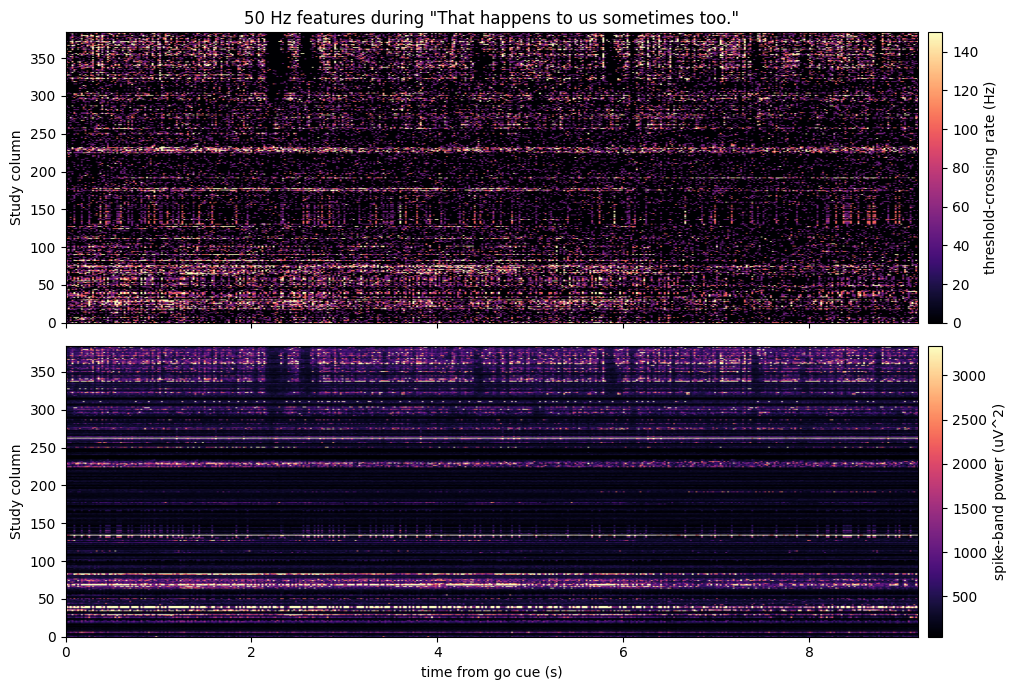

In [10]:
sent = block_events[block_events.type == "Sentence"].iloc[0]
tx_seg = tx_ex(streams, start=float(sent.start), duration=float(sent.duration)).numpy()
sbp_seg = sbp_ex(streams, start=float(sent.start), duration=float(sent.duration)).numpy()
print(f"cue: {sent.text!r} ({sent.duration:.1f} s) -> {tx_seg.shape} and {sbp_seg.shape}")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
panels = [
    (axes[0], tx_seg, "magma", "threshold-crossing rate (Hz)"),
    (axes[1], sbp_seg, "magma", "spike-band power (uV^2)"),
]
for ax, seg, cmap, label in panels:
    im = ax.imshow(
        seg,
        aspect="auto",
        origin="lower",
        cmap=cmap,
        vmin=np.percentile(seg, 2),
        vmax=np.percentile(seg, 98),
        extent=[0, sent.duration, 0, seg.shape[0]],
    )
    ax.set_ylabel("Study column")
    fig.colorbar(im, ax=ax, label=label, pad=0.01)
axes[0].set_title(f'{FS:.0f} Hz features during "{sent.text}"')
axes[1].set_xlabel("time from go cue (s)")
plt.tight_layout()
plt.show()

## 6. The phased contrast through the extractor

For one cued phoneme, read the spike-band power in each phase (read, imagined, attempted) and compare the means. The same cue and three cognitive states, selected only by the `phase` attribute of the unit rows.

cue 'OY' across phases (trial 0):


       read: neural (384, 125) mean SBP   431.9
   imagined: neural (384, 125) mean SBP   442.0
  attempted: neural (384, 125) mean SBP   439.4


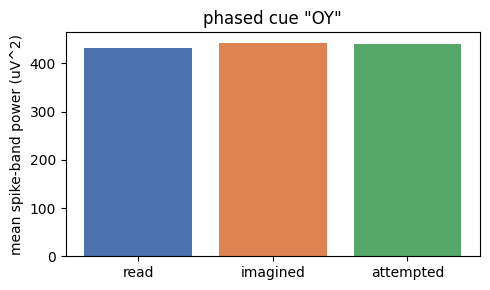

In [11]:
ph_events = events[events.task_family == "phased_phoneme"]
streams_ph = [Event.from_dict(r.to_dict()) for _, r in ph_events[ph_events.type == "BandPower"].iterrows()]

# the first trial's three unit rows, emitted read -> imagined -> attempted, same cue
rows = ph_events[(ph_events.type == "Phoneme") & (ph_events.trial_id == 0)]
cue0 = rows.text.iloc[0]
print(f"cue {cue0!r} across phases (trial 0):")
means = {}
for _, r in rows.iterrows():
    arr = sbp_ex(streams_ph, start=float(r.start), duration=float(r.duration)).numpy()
    means[r.phase] = float(arr.mean())
    print(f"  {r.phase:>9}: neural {arr.shape} mean SBP {arr.mean():7.1f}")

plt.figure(figsize=(5, 3))
plt.bar(list(means), list(means.values()), color=["#4c72b0", "#dd8452", "#55a868"])
plt.ylabel("mean spike-band power (uV^2)")
plt.title(f'phased cue "{cue0}"')
plt.tight_layout()
plt.show()

## 7. The cue catalogue

One unit row per task family with its windowed `start` and `duration`, its filterable attributes (`vocab`, `loop_type`, `task_condition`) and the dataset-wide class id `code`, which rides the cue `Stimulus` of the trial.

In [12]:
# the dataset-wide class id rides the cue Stimulus of each trial
go_kinds = ["speech_go_cue", "movement_go_cue"]
cue_stimuli = events[(events.type == "Stimulus") & ~events.stimulus_kind.isin(go_kinds)]
cue_codes = cue_stimuli.groupby(["timeline", "trial_id"]).code.first()

unit_types = ["Phoneme", "Word", "Sentence", "Action"]
samples = []
for fam in ["orofacial", "phoneme", "word", "sentence_50w_cl", "sentence_125k_ol"]:
    g = events[(events.task_family == fam) & events.type.isin(unit_types)]
    r = g.iloc[0]
    samples.append(
        {
            "task_family": fam,
            "type": r.type,
            "vocab": r.vocab,
            "loop": r.loop_type,
            "task_condition": r.task_condition,
            "code": int(cue_codes[(r.timeline, r.trial_id)]),
            "dur_s": round(float(r.duration), 2),
            "description": r.description,
            "text": r.text,
        }
    )
display(pd.DataFrame(samples))

,task_family,type,vocab,loop,task_condition,code,dur_s,description,text
0,orofacial,Action,na,open,attempted,51,2.00,Push tongue to FRONT roof of your mouth,NaN
1,phoneme,Phoneme,na,open,attempted,4,2.01,thOUGHt,AO
2,word,Word,50w,open,attempted,107,5.05,COMFORTABLE,COMFORTABLE
3,sentence_50w_cl,Sentence,50w,closed,attempted,-100,6.93,They hope I have my nurse.,They hope I have my nurse.
4,sentence_125k_ol,Sentence,125k,open,attempted,-100,9.17,That happens to us sometimes too.,That happens to us sometimes too.


### Cue targets through the extractors

Every `Phoneme`, `Word` and `Sentence` row carries `phonemes`, its ARPAbet target in the frozen 41-class vocabulary (blank 0, the 39 symbols, `|` as the word boundary), the same ids and layout `card_2024` uses. For sentences and words it is the prompt's dictionary pronunciation from `assets/cue_phonemes.json`, for the isolated phoneme blocks it equals `text`. `PhonemeEncoder` reads that field into a variable-length id sequence for a CTC loss. `LabelEncoder` turns the `text` of the `Word` rows and the `description` of the `Action` rows into block-local class indices, and `code` already carries the dataset-wide class id.

In [13]:
phon = PhonemeEncoder(event_types=("Phoneme", "Word", "Sentence"))
print("vocab:", phon.vocab)
for type_ in ["Phoneme", "Word", "Sentence"]:
    r = events[events.type == type_].iloc[0]
    ev = Event.from_dict(r.to_dict())
    ids = phon.get_static(ev).tolist()
    print(f"  {type_:8s} {r.text!r:36s} -> {r.phonemes!r}")
    print(f"  {'':8s} ids {ids}")

for type_, field in [("Word", "text"), ("Action", "description")]:
    rows = events[events.type == type_]
    enc = LabelEncoder(event_types=type_, event_field=field)
    evs = [Event.from_dict(r.to_dict()) for _, r in rows.iterrows()]
    enc.prepare(evs)
    first = rows.iloc[0]
    print(f"{type_} {field}: {len(evs)} events, {enc._n_classes} classes, e.g. {first[field]!r} -> {enc.get_static(evs[0]).tolist()} | code {int(cue_codes[(first.timeline, first.trial_id)])}")

vocab: PhonemeVocab(version='v1', n_classes=41)
  Phoneme  'AO'                                 -> 'AO'
           ids [4]
  Word     'COMFORTABLE'                        -> 'K AH M F ER T AH B AH L |'
           ids [20, 3, 22, 14, 12, 31, 3, 7, 3, 21, 40]
  Sentence 'They hope I have my nurse.'         -> 'DH EY | HH OW P | AY | HH AE V | M AY | N ER S |'
           ids [10, 13, 40, 16, 25, 27, 40, 6, 40, 16, 2, 35, 40, 22, 6, 40, 23, 12, 29, 40]
Word text: 50 events, 50 classes, e.g. 'COMFORTABLE' -> [6] | code 107
Action description: 38 events, 18 classes, e.g. 'DO_NOTHING' -> [1] | code 40


## Summary

- **`Jude2026IntendedSpeech`**: 121 timelines, one per task block, over 14 sessions.
- Each emits `SpikeCounts` and `BandPower` (384 or 256 channels, 100 Hz, Study order) over the whole block, plus per trial a cue `Stimulus`, a go cue and the cued unit (`Phoneme`, `Word`, `Sentence` or `Action`) windowed from the go cue to the trial end. The phased session adds the read / imagined / attempted contrast on `task_condition` and `phase`.
- `NeuralFeatureExtractor` reads each stream at the decoder rate. `Phoneme`, `Word` and `Sentence` rows carry `phonemes` in the frozen 41-class vocabulary, so `PhonemeEncoder` gives a CTC target that pools with `card_2024`. `LabelEncoder` and `code` give class ids for the word and movement blocks.
- Filter by attribute (`task_family`, `vocab`, `loop_type`, `task_condition`, `phase`, `valid`) at query time, and select neural or cue rows by event **type**.
- `03_model_example.ipynb` trains a sentence-level CTC decoder on the 125k task with one session held out.